# 01 - The data and the users

**Goal of this notebook:** get to know the data before we use it. We look at (1) what is in the extract and how parquet files are read, and (2) which users we work with.

It does not save anything. Notebook 02 builds on what we learn here.

## 1. Setup

In [1]:
%pip install -q duckdb

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

# The folder with the extract on this computer (it is not in git, it is too big)
EXTRACT = Path("/Users/hanshornbek/Desktop/Projects/Data Mining project/Extract")
YEAR = 2026

con = duckdb.connect()      # DuckDB: a tool that runs SQL queries directly on files. We use it for everything big.

def run(sql):
    """Run a SQL statement that creates or saves something (CREATE TABLE, COPY, PRAGMA) and finish it completely."""
    con.execute(sql).fetchall()

def scalar(sql):
    """Run a query that returns one number, and give back that number."""
    return con.execute(sql).fetchall()[0][0]

## 2. What is in the extract?

The listens are stored as **parquet files**, one folder per year: `extract/year=2002`, `extract/year=2003`, ... A parquet file is like a csv, but stored in columns, compressed and typed - which makes it much smaller and faster to read. A csv with this much data would be too big to handle.

In [3]:
year_folders = sorted((EXTRACT / "extract").glob("year=*"))
print(f"{len(year_folders)} years: {year_folders[0].name} to {year_folders[-1].name}")

files = sorted((EXTRACT / "extract" / f"year={YEAR}").glob("*.parquet"))
total_gb = sum(f.stat().st_size for f in files) / 1e9
print(f"year {YEAR}: {len(files)} files, {total_gb:.1f} GB")

25 years: year=2002 to year=2026
year 2026: 39 files, 7.3 GB


## 3. Look inside one file

`DESCRIBE` shows the columns and their types. `count(*)` counts the rows. DuckDB reads only what it needs, so this is instant.

In [4]:
one = files[0]
n_rows = scalar(f"SELECT count(*) FROM read_parquet('{one}')")
print(f"rows in the first file: {n_rows:,}")
con.sql(f"DESCRIBE SELECT * FROM read_parquet('{one}')").df()[["column_name", "column_type"]]

rows in the first file: 1,024,896


,column_name,column_type
0,user_id,BIGINT
1,ts,BIGINT
2,year,BIGINT
3,artist_name,VARCHAR
4,track_name,VARCHAR
5,release_name,VARCHAR
6,recording_msid,VARCHAR
7,recording_mbid,VARCHAR
8,release_mbid,VARCHAR
9,artist_mbid,VARCHAR


There are 20 columns. We only use these:

| column | what it is |
|---|---|
| `user_id` | the listener (a number, anonymous) |
| `ts` | the time of the listen: seconds since 1 January 1970, UTC |
| `artist_name`, `track_name` | what ListenBrainz knows about the song |
| `recording_mbid`, `artist_mbid`, `release_mbid` | MusicBrainz ids for the song, artist and release - **only about 5% of the listens have them** |

There is **no genre column**. Genres have to be found through MusicBrainz, which is what notebook 02 does.

## 4. The first rows

In [5]:
con.sql(f"""
    SELECT user_id, to_timestamp(ts) AS time_utc, ts, artist_name, track_name,
           recording_mbid, artist_mbid, release_mbid
    FROM read_parquet('{one}')
    LIMIT 8
""").df()

,user_id,time_utc,ts,artist_name,track_name,recording_mbid,artist_mbid,release_mbid
0,138536,2026-01-01 01:00:00+01:00,1767225600,Maxim & Matte & House of Prayers,All Night (Radio Mix),None,None,None
1,138536,2026-01-01 01:00:00+01:00,1767225600,Crazibiza,Alegres (Radio Mix),None,None,None
2,138536,2026-01-01 01:00:00+01:00,1767225600,Thom Brown,Passion,None,None,None
3,138536,2026-01-01 01:00:00+01:00,1767225600,Black Blood & Crazibiza,Take It Easy (Efendi Remix),None,None,None
4,138536,2026-01-01 01:00:00+01:00,1767225600,Effendi & Crazibiza,Be My Lover (Effendisco Remix),None,None,None
5,138536,2026-01-01 01:00:00+01:00,1767225600,Crazibiza,Back2House,None,None,None
6,138536,2026-01-01 01:00:00+01:00,1767225600,DjM,Besame Mucho,None,None,None
7,138536,2026-01-01 01:00:00+01:00,1767225600,Crazibiza & Cheesecake Boys,Boogie & Bounce,None,None,None


`to_timestamp(ts)` turns the number into a readable time. Notice that several listens can have exactly the same second: they are different songs, uploaded in one batch.

How many of the listens have a MusicBrainz id?

In [ ]:
con.sql(f"""
    SELECT round(100 * avg((recording_mbid IS NOT NULL)::INT), 1) AS pct_with_recording_id,
           round(100 * avg((artist_mbid IS NOT NULL)::INT), 1)    AS pct_with_artist_id,
           round(100 * avg((release_mbid IS NOT NULL)::INT), 1)   AS pct_with_release_id
    FROM read_parquet('{one}')
""").df()

,pct_with_recording_id,pct_with_artist_id,pct_with_release_id
0,5.3,5.1,5.1


## 5. The users

The extract does not contain all ListenBrainz users - only a **cohort** of 13,515 users who have a long, steady history (at least 5 years in a row with 2,000-40,000 listens per year). Two small csv files describe them.

In [ ]:
users = pd.read_csv(EXTRACT / "cohort_users.csv")
print(f"{len(users):,} users, {users['total_listens'].sum():,} listens in total")
users.head()

13,515 users, 1,462,060,308 listens in total


,user_id,window_start,window_end,first_year,last_year,n_runs,total_listens,bucket
0,1,2009,2025,2006,2026,1,220287,11
1,2,2013,2024,2012,2024,1,153130,12
2,5,2017,2026,2006,2026,1,172985,93
3,8,2021,2025,2010,2025,1,75650,1
4,9,2007,2011,2007,2026,2,143901,74


The column `bucket` (0-99) gives every user a fixed random number (computed from the user id). It is random but repeatable: the same user always has the same bucket. We use it to take a sample of users:

- buckets **0-9**: the **development users** (about 10%), where we build and test everything
- buckets 10-19: validation users, to check our findings later
- the rest: for the final run on everyone

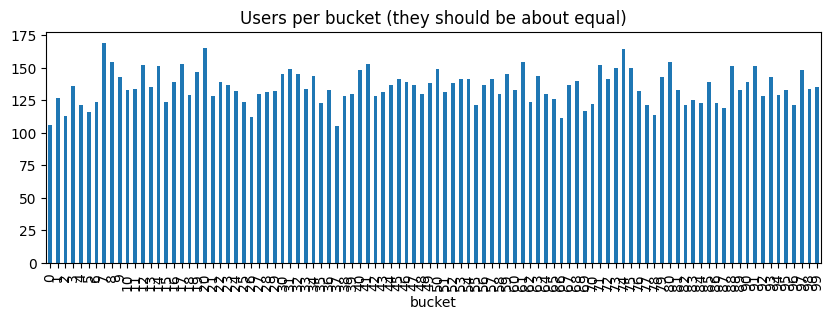

1,309 development users, with 9.6% of all listens


In [ ]:
users["bucket"].value_counts().sort_index().plot(kind="bar", figsize=(10, 3), title="Users per bucket (they should be about equal)")
plt.show()

dev_users = users[users["bucket"] < 10]
print(f"{len(dev_users):,} development users, with {dev_users['total_listens'].sum() / users['total_listens'].sum() * 100:.1f}% of all listens")

## 6. How much is there per year?

`cohort_year_counts.csv` says how many listens each user has in each year. This helps us decide which years to include: early years have few users, so their genre shares are noisy. 2026 only runs until the end of October.

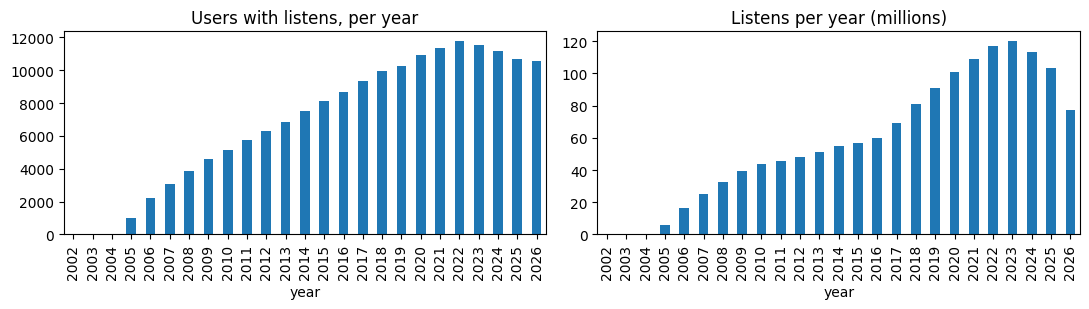

,users,listens
year,,
2019,10279,91051018
2020,10904,101120712
2021,11367,108714353
2022,11777,117210953
2023,11529,120162160
2024,11183,113445264
2025,10671,103273091
2026,10556,77003301


In [ ]:
year_counts = pd.read_csv(EXTRACT / "cohort_year_counts.csv")        # user_id, year, listens
per_year = year_counts.groupby("year").agg(users=("user_id", "nunique"), listens=("listens", "sum"))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.2))
per_year["users"].plot(kind="bar", ax=a1, title="Users with listens, per year")
(per_year["listens"] / 1e6).plot(kind="bar", ax=a2, title="Listens per year (millions)")
plt.tight_layout(); plt.show()
per_year.tail(8)

## 7. Keep only the development users, inside DuckDB

To select the development users when we read the parquet files, we give DuckDB the user list (`register`) and use it in the query with `WHERE user_id IN (...)`. Test on one file:

In [ ]:
con.register("dev_users", dev_users[["user_id"]])

con.sql(f"""
    SELECT count(*) AS listens_kept, count(DISTINCT user_id) AS users_kept
    FROM read_parquet('{one}')
    WHERE user_id IN (SELECT user_id FROM dev_users)
""").df()

,listens_kept,users_kept
0,105972,871


## What to notice

- The extract is parquet, one folder per year, and has **no genre column**.
- We work with the **development users** (buckets 0-9): about 10% of the users and listens. The final run drops the filter.
- DuckDB reads and filters the parquet files directly, without loading everything into memory. That is what makes the full run possible.
- Early years have few users. Which years to include in the evolution is something we decide later.